In [64]:
import pdfplumber
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Extracting Data with `pdfplumber` and Saving as csv

`pdfplumber` is too messy, almost gave up on it and resorted to manual data entry

spent 2 days on it btw

In [86]:
# Defining the extraction function
def extract_statement(pdf_path, keywords, label, output_csv, preview_rows=5):
    """
    This function searches a given document for the balance sheet and profit and loss statements, 
    selects the second candidate (which is usually most likely correct) and saves both to csv files
    """
    # this list collects all possible balance sheet candidates
    matched_tables = []
    with pdfplumber.open(pdf_path) as pdf:
        print(f"{label} search in {pdf_path}\n Total pages: {len(pdf.pages)}")
        for i, page in enumerate(pdf.pages):
            text = page.extract_text() or ""
            # check if all keywords appear in the balance sheet and pl statements
            if all(k in text for k in keywords):
                print(f" {label} candidate found on page: {i}")
                table = page.extract_table({
                    "vertical_strategy": "text",
                    "horizontal_strategy": "text"
                })
                # preview candidate tables and append them to the list
                if table:
                    print(f" Preview of {label} table (page {i}):")
                    for row in table[:preview_rows]:
                        print(row)
                    matched_tables.append((i, table))
                else:
                    print(f" No table detected on page {i}")

    if matched_tables:
        # pick the last match (likely the right one)
        page_num, table = matched_tables[-1]
        print(f" Saving {label} from page {page_num}")
        df = pd.DataFrame(table)
        df.to_csv(output_csv, index=False)
    else:
        print(f" No {label} table found")
        return None

bs_keywords = ["Statements of Financial Position", "Total assets", "Total liabilities", "Equity"]
pl_keywords = ["Statements of Profit or Loss", "Operating income", "Interest income"]

In [88]:
# 2025 document
extract_statement("data/raw/gcb_annual_report_2025.pdf", bs_keywords,
                  "Balance Sheet", "data/raw/2025-2024_balance_sheet.csv")
extract_statement("data/raw/gcb_annual_report_2025.pdf", pl_keywords,
                  "Profit and Loss", "data/raw/2025-2024_profit_and_loss.csv")

Balance Sheet search in data/raw/gcb_annual_report_2025.pdf
 Total pages: 208
 Balance Sheet candidate found on page: 34
 Preview of Balance Sheet table (page 34):
['Figures in thousands', 'of Ghana Cedis', '2025', '2024', '2023', '2022', '2021']
['', '', '', '', '', '', '']
['Intangible assets', '', '170,549', '178,486', '76,043', '123,752', '168,226']
['', '', '', '', '', '', '']
['Other assets', '', '940,668', '924,892', '638,280', '902,983', '536,552']
 Balance Sheet candidate found on page: 87
 Preview of Balance Sheet table (page 87):
['Figures in thou', 'san', 'ds of Ghana Cedis', 'Note', 'Bank', 'Group', 'Bank', 'Group']
['', '', '', '', '', '', '', '']
['Assets', '', '', '', '', '', '', '']
['', '', '', '', '', '', '', '']
['Cash and cash', 'eq', 'uivalents', '21', '14,451,217', '14,451,219', '14,443,976', '14,443,976']
 Saving Balance Sheet from page 87
Profit and Loss search in data/raw/gcb_annual_report_2025.pdf
 Total pages: 208
 Profit and Loss candidate found on page: 85

In [89]:
# 2023 document
extract_statement("data/raw/gcb_annual_report_2023.pdf", bs_keywords,
                  "Balance Sheet", "data/raw/2023-2022_balance_sheet.csv")
extract_statement("data/raw/gcb_annual_report_2023.pdf", pl_keywords,
                  "Profit and Loss", "data/raw/2023-2022_profit_and_loss.csv")

Balance Sheet search in data/raw/gcb_annual_report_2023.pdf
 Total pages: 192
 Balance Sheet candidate found on page: 76
 Preview of Balance Sheet table (page 76):
['', '', '', '', '2023', '', '2022']
['', '', '', '', '', '', '']
['Figures in thou', 'sands of Ghana Cedis N', 'ote(s)', 'Bank', 'Group', 'Bank', 'Group']
['', '', '', '', '', '', '']
['Assets', '', '', '', '', '', '']
 Saving Balance Sheet from page 76
Profit and Loss search in data/raw/gcb_annual_report_2023.pdf
 Total pages: 192
 Profit and Loss candidate found on page: 74
 Preview of Profit and Loss table (page 74):
['Stateme', 'nts', 'of Profi', 't or', 'Loss a', 'nd O', 'ther', '']
['Compre', 'hens', 'ive Inc', 'ome', '', '', '', '']
['', '', '', '', '', '', '', '']
['', '', '', '', '', '', '', '75']
['', '', '', '', '', '', '', '']
 Saving Profit and Loss from page 74


In [90]:
# 2021 document
extract_statement("data/raw/gcb_annual_report_2021.pdf", bs_keywords,
                  "Balance Sheet", "data/raw/2021_balance_sheet.csv")
extract_statement("data/raw/gcb_annual_report_2021.pdf", pl_keywords,
                  "Profit and Loss", "data/raw/2021_profit_and_loss.csv")

Balance Sheet search in data/raw/gcb_annual_report_2021.pdf
 Total pages: 176
 Balance Sheet candidate found on page: 21
 Preview of Balance Sheet table (page 21):
['All figures are in thou', 'sands of Ghana Cedis', '', '2021', '', '2020', '2019', '2018', '', '2017']
['', '', '', '', '', '', '', '', '', '']
['Assets', '', '', '', '', '', '', '', '', '']
['', '', '', '', '', '', '', '', '', '']
['Cash and cash equiva', 'lents', '', '2,301,092', '', '1,567,241', '1,572,538', '1,953,620', '', '1,022,684']
 Balance Sheet candidate found on page: 60
 Preview of Balance Sheet table (page 60):
['', '', '', '', '2021', '', '2020']
['', '', '', '', '', '', '']
['Figures in thousands', 'of Ghana Cedis', 'Note', 'Bank', 'Group', 'Bank', 'Group']
['', '', '', '', '', '', '']
['Assets', '', '', '', '', '', '']
 Saving Balance Sheet from page 60
Profit and Loss search in data/raw/gcb_annual_report_2021.pdf
 Total pages: 176
 Profit and Loss candidate found on page: 58
 Preview of Profit and Loss tab

## Importing and Previewing Statements

In [119]:
bs_25_24 = pd.read_csv("data/raw/2025-2024_balance_sheet.csv")
bs_25_24.head()

,0,1,2,3,4,5,6,7
0,Figures in thou,san,ds of Ghana Cedis,Note,Bank,Group,Bank,Group
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Assets,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Cash and cash,eq,uivalents,21,"14,451,217","14,451,219","14,443,976","14,443,976"


In [92]:
pl_25_24 = pd.read_csv("data/raw/2025-2024_profit_and_loss.csv")
pl_25_24.head()

,0,1,2,3,4,5,6,7
0,A,nnual Repor,t,NaN,NaN,NaN,NaN,NaN
1,2,025,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,S,tateme,nts of Profit or Loss,and,Other C,ompreh,ensive,Incom
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [93]:
bs_23_22 = pd.read_csv("data/raw/2023-2022_balance_sheet.csv")
bs_23_22.head()

,0,1,2,3,4,5,6
0,NaN,NaN,NaN,NaN,2023,NaN,2022
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Figures in thou,sands of Ghana Cedis N,ote(s),Bank,Group,Bank,Group
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Assets,NaN,NaN,NaN,NaN,NaN,NaN


In [97]:
pl_23_22 = pd.read_csv("data/raw/2023-2022_profit_and_loss.csv")
pl_23_22.head(10)

,0,1,2,3,4,5,6,7
0,Stateme,nts,of Profi,t or,Loss a,nd O,ther,NaN
1,Compre,hens,ive Inc,ome,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,75
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,or the year ende,d 31 Dece,mber 2023,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,2023,NaN,2022
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Figures in thousands o,f Ghana Ced,is N,ote(s),Bank,Group,Bank,Group


In [95]:
bs_21 = pd.read_csv("data/raw/2021_balance_sheet.csv")
bs_21.head()

,0,1,2,3,4,5,6
0,NaN,NaN,NaN,NaN,2021,NaN,2020
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Figures in thousands,of Ghana Cedis,Note,Bank,Group,Bank,Group
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Assets,NaN,NaN,NaN,NaN,NaN,NaN


In [96]:
pl_21 = pd.read_csv("data/raw/2021_profit_and_loss.csv")
pl_21.head()

,0,1,2,3,4,5,6,7
0,NaN,Statements,of Profit o,r Los,s and O,ther,NaN,NaN
1,NaN,Comprehen,sive Inco,me,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,F,or the year ended,31 December 2,021,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Cleaning and Joining the Statements to Create the Manual

### 2025-2024

In [234]:
# create a copy of the df for cleaning
bs_25_24_cleaned = bs_25_24.copy()

# drop rows with all null cells
bs_25_24_cleaned = bs_25_24_cleaned.dropna(how="all")

# join columns 0, 1, 2, with .fillna() to prevent errors
bs_25_24_cleaned["items"] = bs_25_24_cleaned.fillna('')["0"] + bs_25_24_cleaned.fillna('')["1"] + bs_25_24_cleaned.fillna('')["2"]

# drop redundant columns (0, 1, 2, Notes to statement column, Group financials column)
bs_25_24_cleaned = bs_25_24_cleaned.drop(["0", "1", "2", "3", "5", "7"], axis=1)

# drop largely empty title rows and errored ones
bs_25_24_cleaned = bs_25_24_cleaned.drop([0, 2, 30, 46, 64])

# set "items" column as index
bs_25_24_cleaned = bs_25_24_cleaned.set_index("items")

# rename the columns to reflect their years
bs_25_24_cleaned.columns = ["2025", "2024"]

bs_25_24_cleaned.to_csv("data/raw/2025-2024_balance_sheet_cleaned.csv")

bs_25_24_cleaned.head()

,2025,2024
items,,
Cash and cashequivalents,"14,451,217","14,443,976"
Non-pledged trading assets,"2,501,311","713,794"
Investments inequity instruments,"30,667","7,628"
Loans and advances to customers,"16,038,002","10,229,504"
Advances to banks,"349,627","1,108,837"


In [238]:
pl_25_24_cleaned = pl_25_24.copy()
pl_25_24_cleaned = pl_25_24_cleaned.dropna(how="all")

# join columns 0, 1, 2, with .fillna() to prevent errors
pl_25_24_cleaned["items"] = pl_25_24_cleaned.fillna('')["0"] + pl_25_24_cleaned.fillna('')["1"] + pl_25_24_cleaned.fillna('')["2"]

# drop redundant columns (0, 1, 2, Notes to statement column, Group financials column)
pl_25_24_cleaned = pl_25_24_cleaned.drop(["0", "1", "2", "3", "5", "7"], axis=1)

# drop largely empty title rows and errored ones
pl_25_24_cleaned = pl_25_24_cleaned.drop([0, 1, 3, 5, 7, 9, 31, 32, 44, 52])

# set "items" column as index
pl_25_24_cleaned = pl_25_24_cleaned.set_index("items")

# rename the columns to reflect their years
pl_25_24_cleaned.columns = ["2025", "2024"]

pl_25_24_cleaned.to_csv("data/raw/2025-2024_profit_and_loss_cleaned.csv")

pl_25_24_cleaned.head()

,2025,2024
items,,
Interest income,"6,136,361","4,441,387"
Interest expense,"(1,571,799)","(1,065,965)"
Net interest income,"4,564,562","3,375,422"
Fee and commission income,"1,131,697","780,431"
Fee and commission expense,"(285,354)","(176,965)"


### 2023-2022

In [239]:
# create a copy of the df for cleaning
bs_23_22_cleaned = bs_23_22.copy()

# drop rows with all null cells
bs_23_22_cleaned = bs_23_22_cleaned.dropna(how="all")

# join columns 0, 1, 2, with .fillna() to prevent errors
bs_23_22_cleaned["items"] = bs_23_22_cleaned.fillna('')["0"] + bs_23_22_cleaned.fillna('')["1"]

# drop redundant columns (0, 1, 2, Notes to statement column, Group financials column)
bs_23_22_cleaned = bs_23_22_cleaned.drop(["0", "1", "2", "4", "6"], axis=1)

# drop largely empty title rows and errored ones
bs_23_22_cleaned = bs_23_22_cleaned.drop([0, 2, 4, 34, 37, 51, 69])

# set "items" column as index
bs_23_22_cleaned = bs_23_22_cleaned.set_index("items")

# rename the columns to reflect their years
bs_23_22_cleaned.columns = ["2023", "2022"]

bs_23_22_cleaned.to_csv("data/raw/2023-2022_balance_sheet_cleaned.csv")

bs_23_22_cleaned.head()

,2023,2022
items,,
Cash and cashequivalents,"5,653,778","4,476,878"
Non-pledged trading assets,"319,065","275,992"
Investments (other than securities),"3,942","4,277"
Loans and advances to customers,"6,692,514","5,482,215"
Advances to banks,"382,642","229,115"


In [240]:
# create a copy of the df for cleaning
pl_23_22_cleaned = pl_23_22.copy()

# drop rows with all null cells
pl_23_22_cleaned = pl_23_22_cleaned.dropna(how="all")

# join columns 0, 1, 2, with .fillna() to prevent errors
pl_23_22_cleaned["items"] = pl_23_22_cleaned.fillna('')["0"] + pl_23_22_cleaned.fillna('')["1"]

# drop redundant columns (0, 1, 2, Notes to statement column, Group financials column)
pl_23_22_cleaned = pl_23_22_cleaned.drop(["0", "1", "2", "3", "5", "7"], axis=1)

# drop largely empty title rows and errored ones
pl_23_22_cleaned = pl_23_22_cleaned.drop([0, 1, 3, 5, 7, 9, 41, 49,51, 52, 54, 55, 
                                          57, 59, 60, 62, 63, 65, 67, 68, 70, 71, 73])

# set "items" column as index
pl_23_22_cleaned = pl_23_22_cleaned.set_index("items")

# rename the columns to reflect their years
pl_23_22_cleaned.columns = ["2023", "2022"]

pl_23_22_cleaned.to_csv("data/raw/2023-2022_profit_and_loss_cleaned.csv")

pl_23_22_cleaned.head()

,2023,2022
items,,
Interest income,"3,731,778","2,813,805"
Interest expense,"(860,609)","(722,006)"
Net interest income,"2,871,169","2,091,799"
Fee and commission income,"546,828","439,224"
Fee and commission expense,"(116,862)","(66,630)"


### 2021

In [241]:
# create a copy of the df for cleaning
bs_21_cleaned = bs_21.copy()

# drop rows with all null cells
bs_21_cleaned = bs_21_cleaned.dropna(how="all")

# join columns 0, 1, 2, with .fillna() to prevent errors
bs_21_cleaned["items"] = bs_21_cleaned.fillna('')["0"] + bs_21_cleaned.fillna('')["1"]

# drop redundant columns (0, 1, 2, Notes to statement column, Group financials column)
bs_21_cleaned = bs_21_cleaned.drop(["0", "1", "2", "4", "5", "6"], axis=1)

# drop largely empty title rows and errored ones
bs_21_cleaned = bs_21_cleaned.drop([0, 2, 4, 31, 35, 38, 52, 66, 68, 69])

# set "items" column as index
bs_21_cleaned = bs_21_cleaned.set_index("items")

# rename the columns to reflect their years
bs_21_cleaned.columns = ["2021"]

bs_21_cleaned.to_csv("data/raw/2021_balance_sheet_cleaned.csv")

bs_21_cleaned.head()

,2021
items,
Cash and cash equivalents,"2,301,092"
Non-pledged tradingassets,"477,658"
Investments (other than securities),"3,779"
Loans and advances to customers,"4,306,380"
Advances to banks,"201,030"


In [242]:
# create a copy of the df for cleaning
pl_21_cleaned = pl_21.copy()

# drop rows with all null cells
pl_21_cleaned = pl_21_cleaned.dropna(how="all")

# join columns 0, 1, 2, with .fillna() to prevent errors
pl_21_cleaned["items"] = pl_21_cleaned.fillna('')["0"] + pl_21_cleaned.fillna('')["1"] + pl_21_cleaned.fillna('')["2"]

# drop redundant columns (0, 1, 2, Notes to statement column, Group financials column)
pl_21_cleaned = pl_21_cleaned.drop(["0", "1", "2", "3", "5", "6", "7"], axis=1)

# drop largely empty title rows and errored ones
pl_21_cleaned = pl_21_cleaned.drop([0, 1, 3, 5, 7, 37])

# set "items" column as index
pl_21_cleaned = pl_21_cleaned.set_index("items")

# rename the columns to reflect their years
pl_21_cleaned.columns = ["2021"]

pl_21_cleaned.to_csv("data/raw/2021_profit_and_loss_cleaned.csv")

pl_21_cleaned.head()

,2021
items,
Interest income,"2,369,457"
Interest expense,"(484,620)"
Net interest income,"1,884,837"
Fee and commission income,"390,408"
Fee and commission expense,"(50,749)"


In [16]:
bs_25_24_cleaned = pd.read_csv("data/raw/2025-2024_balance_sheet_cleaned.csv", index_col="items")
pl_25_24_cleaned = pd.read_csv("data/raw/2025-2024_profit_and_loss_cleaned.csv", index_col="items")
bs_23_22_cleaned = pd.read_csv("data/raw/2023-2022_balance_sheet_cleaned.csv", index_col="items")
pl_23_22_cleaned = pd.read_csv("data/raw/2023-2022_profit_and_loss_cleaned.csv", index_col="items")
bs_21_cleaned = pd.read_csv("data/raw/2021_balance_sheet_cleaned.csv", index_col="items")
pl_21_cleaned = pd.read_csv("data/raw/2021_profit_and_loss_cleaned.csv", index_col="items")

### Joining

In [49]:
bs_25_24_cleaned.shape, bs_23_22_cleaned.shape, bs_21_cleaned.shape

((28, 2), (28, 2), (27, 1))

In [17]:
# unifying balance sheet labels to facilitate joining
bs_23_22_cleaned = bs_23_22_cleaned.rename(index={"Investments (other than securities)": "Investments inequity instruments", 
                                                  "Deposits frombanks & other financial": "Deposits fromfinancial institutions",
                                                  "Employee benefit obligation": "Employee benefitobligation"})
bs_23_22_cleaned = bs_23_22_cleaned.drop(["Current tax assets"])

bs_21_cleaned = bs_21_cleaned.rename(index={"Cash and cash equivalents": "Cash and cashequivalents", 
                                            "Non-pledged tradingassets": "Non-pledged trading assets",
                                            "Investments (other than securities)": "Investments inequity instruments",
                                            "Investments in associates": "Investments inassociates",
                                            "Investments in subsidiary": "Investments insubsidiary",
                                            "Property, equipmentand right-of-use": "Property, equipment and ROU",
                                            "Deposits from banks& other financial": "Deposits fromfinancial institutions",
                                            "Deposits from customers": "Deposits fromcustomers",
                                            "Employee benefit obligation": "Employee benefitobligation",
                                            "Statutory reserve": "Statutory reserves",
                                            "Fair value reserve": "Fair value reserves",
                                           "Total shareholders’equity": "Total shareholders’ equity",})
bs_21_cleaned = bs_21_cleaned.drop(["Current tax assets"])

# adding a new row, value copied from source document
bs_21_cleaned.loc["Total liabilitiesand shareholders’ equity"] = [18260281]

In [18]:
# joining all three
complete_bs = pd.concat([bs_25_24_cleaned, bs_23_22_cleaned, bs_21_cleaned], axis=1)
complete_bs.head()

,2025,2024,2023,2022,2021
items,,,,,
Cash and cashequivalents,"14,451,217","14,443,976","5,653,778","4,476,878","2,301,092"
Non-pledged trading assets,"2,501,311","713,794","319,065","275,992","477,658"
Investments inequity instruments,"30,667","7,628","3,942","4,277","3,779"
Loans and advances to customers,"16,038,002","10,229,504","6,692,514","5,482,215","4,306,380"
Advances to banks,"349,627","1,108,837","382,642","229,115","201,030"


In [62]:
complete_bs.dtypes

2025    object
2024    object
2023    object
2022    object
2021    object
dtype: object

In [19]:
# remove commas, convert () to negative, convert values to int
cols_to_clean = ["2025", "2024", "2023", "2022", "2021"]

for col in cols_to_clean:
    complete_bs[col] = (complete_bs[col]
                        .astype(str)                                      # ensure all values are strings
                        .str.replace(",", "", regex=True)                 # remove commas
                        .str.replace(r"\((.*)\)", r"-\1", regex=True)     # convert brackets to negatives
                        .str.replace(r"[^\d\-]", "", regex=True)          # remove non-numeric characters like '.' or spaces
                        .replace(["", "-", "."], "0")                     # replace blanks, dashes, and dots with 0
                        .astype(float)                                    # convert to float
                        .astype(int)                                      # final integer type
                        )

In [20]:
complete_bs

,2025,2024,2023,2022,2021
items,,,,,
Cash and cashequivalents,14451217,14443976,5653778,4476878,2301092
Non-pledged trading assets,2501311,713794,319065,275992,477658
Investments inequity instruments,30667,7628,3942,4277,3779
Loans and advances to customers,16038002,10229504,6692514,5482215,4306380
Advances to banks,349627,1108837,382642,229115,201030
Investment securities,16353728,13430047,11834925,8610561,9707421
Investments inassociates,28274,28274,28274,28274,28274
Investments insubsidiary,3750,3750,3000,3000,1000
Deferred tax assets,873626,899707,864942,757825,237927


In [12]:
pl_25_24_cleaned.shape, pl_23_22_cleaned.shape, pl_21_cleaned.shape

((18, 2), (17, 2), (17, 1))

In [11]:
# unifying p/l statement labels to facilitate joining
pl_23_22_cleaned = pl_23_22_cleaned.rename(index={"Net fee and commissionincome": "Net fee and commission income", 
                                                  "Net impairment loss onloans": "Net impairmentloss on loans and advances",
                                                  "Operating profit/(loss)": "Operating profit",
                                                  "Profit/(Loss) before income tax": "Profit before income tax",
                                                  "Profit/(Loss) for the year": "Profit for the year"})
pl_23_22_cleaned = pl_23_22_cleaned.drop(["Net impairment loss onInvestment"])

pl_21_cleaned = pl_21_cleaned.rename(index={"Net fee and commissionincome": "Net fee and commission income", 
                                            "Other operating income": "Other income",
                                            "Net impairment loss onfinancial assets": "Net impairmentloss on loans and advances"})

In [13]:
# joining all three
complete_pl = pd.concat([pl_25_24_cleaned, pl_23_22_cleaned, pl_21_cleaned], axis=1)
complete_pl.head()

,2025,2024,2023,2022,2021
items,,,,,
Interest income,"6,136,361","4,441,387","3,731,778","2,813,805","2,369,457"
Interest expense,"(1,571,799)","(1,065,965)","(860,609)","(722,006)","(484,620)"
Net interest income,"4,564,562","3,375,422","2,871,169","2,091,799","1,884,837"
Fee and commission income,"1,131,697","780,431","546,828","439,224","390,408"
Fee and commission expense,"(285,354)","(176,965)","(116,862)","(66,630)","(50,749)"


In [14]:
# remove commas, convert () to negative, convert values to int
cols_to_clean = ["2025", "2024", "2023", "2022", "2021"]

for col in cols_to_clean:
    complete_pl[col] = (complete_pl[col]
                        .astype(str)                                      # ensure all values are strings
                        .str.replace(",", "", regex=True)                 # remove commas
                        .str.replace(r"\((.*)\)", r"-\1", regex=True)     # convert brackets to negatives
                        .str.replace(r"[^\d\-]", "", regex=True)          # remove non-numeric characters like '.' or spaces
                        .replace(["", "-", "."], "0")                     # replace blanks, dashes, and dots with 0
                        .astype(float)                                    # convert to float
                        .astype(int)                                      # final integer type
                        )

In [34]:
gcb_financials_manual = pd.concat([complete_pl, complete_bs], axis=0)
gcb_financials_manual.to_csv("data/raw/gcb_financials_manual.csv", index=True)

## EDA

In [65]:
df = pd.read_csv("data/cleaned/gcb_financials_manual.csv", index_col="items").T
df.head()

items,Interest income,Interest expense,Net interest income,Fee and commission income,Fee and commission expense,Net fee and commission income,Net trading income,Other income,Operating income,Net impairmentloss on loans and advances,...,Other liabilities,Total liabilities,Stated capital,Retained earnings,Statutory reserves,Credit risk reserves,Fair value reserves,Other reserves,Total shareholders’ equity,Total liabilitiesand shareholders’ equity
2025,6136361,-1571799,4564562,1131697,-285354,846343,824675,26103,6261683,-188797,...,1165431,46389810,500000,4427911,1170459,34460,20061,-144182,6008709,52398519
2024,4441387,-1065965,3375422,780431,-176965,603466,460832,8296,4448016,-427179,...,955577,38531379,500000,2600344,914963,73555,2781,-38679,4052964,42584343
2023,3731778,-860609,2871169,546828,-116862,429966,425065,11532,3737732,-199319,...,864986,24134026,500000,1513806,763818,102074,16,-79095,2800619,26934645
2022,2813805,-722006,2091799,439224,-66630,372594,487226,19792,2971411,-274051,...,586477,19510635,500000,746039,639555,0,267,-39375,1846486,21357121
2021,2369457,-484620,1884837,390408,-50749,339659,157540,9576,2391612,-324800,...,643877,15713249,500000,1434337,639555,0,-106,-26754,2547032,18260281


In [38]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
Index: 5 entries, 2025 to 2021
Data columns (total 46 columns):
 #   Column                                       Non-Null Count  Dtype
---  ------                                       --------------  -----
 0   Interest income                              5 non-null      int64
 1   Interest expense                             5 non-null      int64
 2   Net interest income                          5 non-null      int64
 3   Fee and commission income                    5 non-null      int64
 4   Fee and commission expense                   5 non-null      int64
 5   Net fee and commission income                5 non-null      int64
 6   Net trading income                           5 non-null      int64
 7   Other income                                 5 non-null      int64
 8   Operating income                             5 non-null      int64
 9   Net impairmentloss on loans and advances     5 non-null      int64
 10  Derecognition loss on investm

items,Interest income,Interest expense,Net interest income,Fee and commission income,Fee and commission expense,Net fee and commission income,Net trading income,Other income,Operating income,Net impairmentloss on loans and advances,...,Other liabilities,Total liabilities,Stated capital,Retained earnings,Statutory reserves,Credit risk reserves,Fair value reserves,Other reserves,Total shareholders’ equity,Total liabilitiesand shareholders’ equity
count,5.000000e+00,5.000000e+00,5.000000e+00,5.000000e+00,5.000000,5.000000,5.000000,5.000000,5.000000e+00,5.000000,...,5.000000e+00,5.000000e+00,5.0,5.000000e+00,5.000000e+00,5.000000,5.000000,5.00000,5.000000e+00,5.000000e+00
mean,3.898558e+06,-9.409998e+05,2.957558e+06,6.577176e+05,-139312.000000,518405.600000,471067.600000,15059.800000,3.962091e+06,-282829.200000,...,8.432696e+05,2.885582e+07,500000.0,2.144487e+06,8.256700e+05,42017.800000,4603.800000,-65617.00000,3.451162e+06,3.230698e+07
std,1.487034e+06,4.111652e+05,1.079908e+06,3.046332e+05,95362.590629,209649.196589,237602.530448,7625.818133,1.501868e+06,98096.225397,...,2.358879e+05,1.307108e+07,0.0,1.438711e+06,2.235822e+05,45247.799717,8721.891865,48163.12616,1.636983e+06,1.462331e+07
min,2.369457e+06,-1.571799e+06,1.884837e+06,3.904080e+05,-285354.000000,339659.000000,157540.000000,8296.000000,2.391612e+06,-427179.000000,...,5.864770e+05,1.571325e+07,500000.0,7.460390e+05,6.395550e+05,0.000000,-106.000000,-144182.00000,1.846486e+06,1.826028e+07
25%,2.813805e+06,-1.065965e+06,2.091799e+06,4.392240e+05,-176965.000000,372594.000000,425065.000000,9576.000000,2.971411e+06,-324800.000000,...,6.438770e+05,1.951064e+07,500000.0,1.434337e+06,6.395550e+05,0.000000,16.000000,-79095.00000,2.547032e+06,2.135712e+07
50%,3.731778e+06,-8.606090e+05,2.871169e+06,5.468280e+05,-116862.000000,429966.000000,460832.000000,11532.000000,3.737732e+06,-274051.000000,...,8.649860e+05,2.413403e+07,500000.0,1.513806e+06,7.638180e+05,34460.000000,267.000000,-39375.00000,2.800619e+06,2.693464e+07
75%,4.441387e+06,-7.220060e+05,3.375422e+06,7.804310e+05,-66630.000000,603466.000000,487226.000000,19792.000000,4.448016e+06,-199319.000000,...,9.555770e+05,3.853138e+07,500000.0,2.600344e+06,9.149630e+05,73555.000000,2781.000000,-38679.00000,4.052964e+06,4.258434e+07
max,6.136361e+06,-4.846200e+05,4.564562e+06,1.131697e+06,-50749.000000,846343.000000,824675.000000,26103.000000,6.261683e+06,-188797.000000,...,1.165431e+06,4.638981e+07,500000.0,4.427911e+06,1.170459e+06,102074.000000,20061.000000,-26754.00000,6.008709e+06,5.239852e+07


In [39]:
df

items,Interest income,Interest expense,Net interest income,Fee and commission income,Fee and commission expense,Net fee and commission income,Net trading income,Other income,Operating income,Net impairmentloss on loans and advances,...,Other liabilities,Total liabilities,Stated capital,Retained earnings,Statutory reserves,Credit risk reserves,Fair value reserves,Other reserves,Total shareholders’ equity,Total liabilitiesand shareholders’ equity
2025,6136361,-1571799,4564562,1131697,-285354,846343,824675,26103,6261683,-188797,...,1165431,46389810,500000,4427911,1170459,34460,20061,-144182,6008709,52398519
2024,4441387,-1065965,3375422,780431,-176965,603466,460832,8296,4448016,-427179,...,955577,38531379,500000,2600344,914963,73555,2781,-38679,4052964,42584343
2023,3731778,-860609,2871169,546828,-116862,429966,425065,11532,3737732,-199319,...,864986,24134026,500000,1513806,763818,102074,16,-79095,2800619,26934645
2022,2813805,-722006,2091799,439224,-66630,372594,487226,19792,2971411,-274051,...,586477,19510635,500000,746039,639555,0,267,-39375,1846486,21357121
2021,2369457,-484620,1884837,390408,-50749,339659,157540,9576,2391612,-324800,...,643877,15713249,500000,1434337,639555,0,-106,-26754,2547032,18260281


## **Data Quality Notes**

- It was tough trying to work with pdfplumber, but i got it to work somehow
- Most of the values were extracted using it, but a few had to be done manually in the cleaning and joining section
- A few items were not disclosed consistently throughout the periods, and were either dropped entirely or left where I thought they might be helpful. They include:
  1. current tax assets
  2. current tax liabilities
  3. credit risk reserves
  4. net impairment loss on assets
  5. derecognition loss on investment securities
- The zeroes in the df are from such items, converted from nulls to prevent errors
- Some values were extracted in brackets, the finance way of indicating subtractions or negative values. The brackets were removed and all values arbitrarily converted to negative. This is to be noted for further analysis: a few of them aren't actually negative.
- All figures are in thousands of Ghana cedis

## Analysis
* ROE - calculates how efficiently the bank uses shareholders' capital to generate profit. 10% - 12% is considered baseline.
* ROA - calculates how efficiently the bank uses total assets to generate profit. 1% - 1.2% is considered a target baseline.
* Equity-to-assets - measures the percentage of a bank's total assets funded by its owners' equity rather than customer deposits or borrowed debt. 8% - 12% is considered standard.
* Loan-to-Deposit - evaluates a bank's liquidity by comparing its total volume of active loans to its total base of customer deposits. 80% - 90% is considered healthy.
* Net Profit Margin - gauges a company's overall operational profitability. It measures how much of total revenue remains as pure profit after all expenses, interest and taxes are deducted. 25% - 35% is the industrial benchmark.
* Cost-to-Income Ratio - calculates how much a bank spends on its day-to-day operations to generate one unit of gross income. It is the clearest measure of efficiency banks report and compare against peers. Lower is better here, and the typical baseline is 50% - 60%.

In [66]:
def compute_ratios(df):
    # return on equity
    df["roe"] = df["Profit for the year"] / df["Total shareholders’ equity"]
    # return on asset
    df["roa"] = df["Profit for the year"] / df["Total assets"]
    # profitability
    df["net_profit_margin"] = df["Profit for the year"] / (df["Operating income"])
    # capital adequacy
    df["equity_to_assets"] = df["Total shareholders’ equity"] / df["Total assets"]
    # liquidity
    df["loan_to_deposit"] = df["Loans and advances to customers"] / df["Deposits fromcustomers"]
    # operating expenses
    df["operating_expenses"] = df["Personnel expenses"] + df["Depreciation and amortisation"] + df["Other expenses"]
    df["operating_expenses"] = df["operating_expenses"].abs()
    # efficiency
    df["cost_to_income"] = df["operating_expenses"] / (df["Operating income"])
    return df

df = compute_ratios(df)
df

items,Interest income,Interest expense,Net interest income,Fee and commission income,Fee and commission expense,Net fee and commission income,Net trading income,Other income,Operating income,Net impairmentloss on loans and advances,...,Other reserves,Total shareholders’ equity,Total liabilitiesand shareholders’ equity,roe,roa,net_profit_margin,equity_to_assets,loan_to_deposit,operating_expenses,cost_to_income
2025,6136361,-1571799,4564562,1131697,-285354,846343,824675,26103,6261683,-188797,...,-144182,6008709,52398519,0.340168,0.039008,0.326425,0.114673,0.390711,2935045,0.468731
2024,4441387,-1065965,3375422,780431,-176965,603466,460832,8296,4448016,-427179,...,-38679,4052964,42584343,0.298341,0.028395,0.271843,0.095175,0.300276,2062690,0.463733
2023,3731778,-860609,2871169,546828,-116862,429966,425065,11532,3737732,-199319,...,-79095,2800619,26934645,0.354959,0.036908,0.265964,0.103978,0.310459,1780500,0.476358
2022,2813805,-722006,2091799,439224,-66630,372594,487226,19792,2971411,-274051,...,-39375,1846486,21357121,-0.301003,-0.026024,-0.187049,0.086458,0.312693,1589138,0.534809
2021,2369457,-484620,1884837,390408,-50749,339659,157540,9576,2391612,-324800,...,-26754,2547032,18260281,0.218555,0.030485,0.232758,0.139485,0.327092,1257007,0.525590


## Trend Visualisation

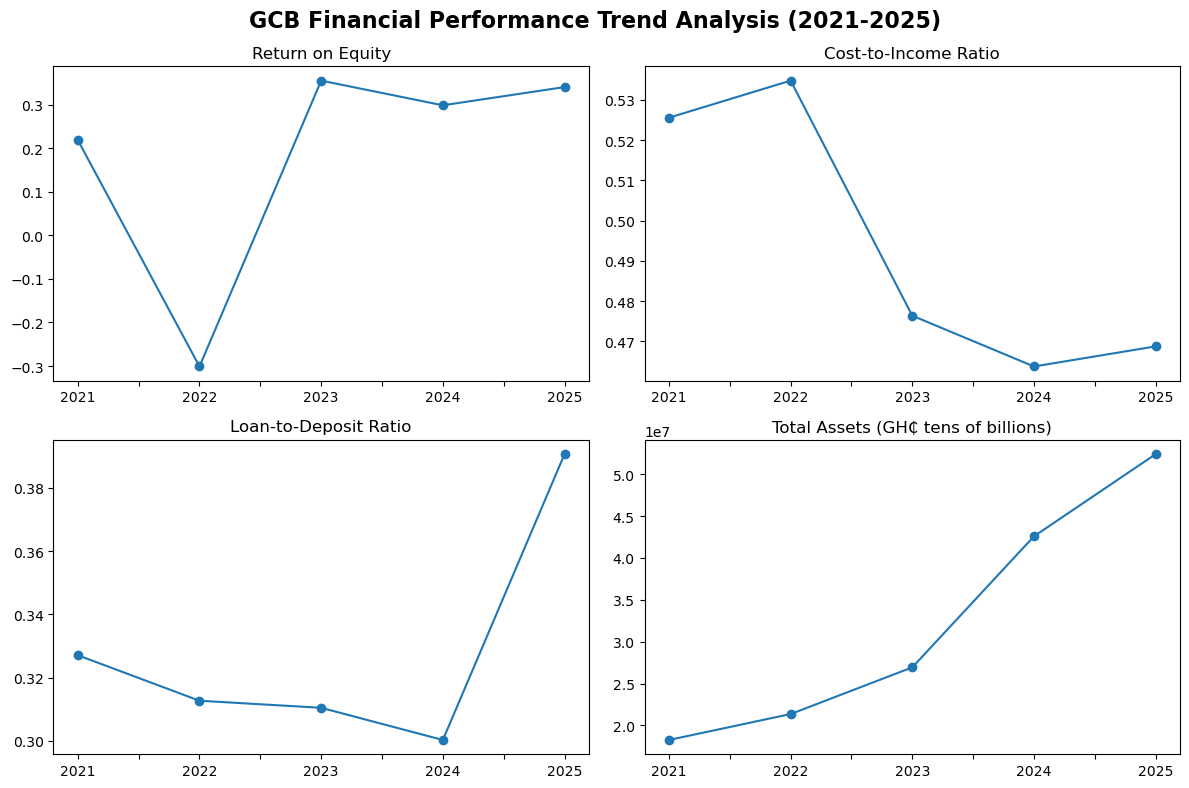

In [68]:
df = df.sort_index(ascending=True)    # sort the years so they appear chronologically

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

df.plot(y="roe", ax=axes[0, 0], marker="o", title="Return on Equity", legend=False)
df.plot(y="cost_to_income", ax=axes[0, 1], marker="o", title="Cost-to-Income Ratio", legend=False)
df.plot(y="loan_to_deposit", ax=axes[1, 0], marker="o", title="Loan-to-Deposit Ratio", legend=False)
df.plot(y="Total assets", ax=axes[1, 1], marker="o", title="Total Assets (GH₵ tens of billions)", legend=False)

fig.suptitle("GCB Financial Performance Trend Analysis (2021-2025)", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig("gcp_trend_analysis.png")
plt.show()

## Interpretation of Financial Performance
Overall, GCB's fiancial efficiency and stability improved by leaps and bounds:
* 2022 was a stress year with losses and reduced returns
* 2023-2025 displayed GCB's recovery in profitability and capitalisation
* Together, the trends highlight a transition from vulnerability to sustainable growth.

1. Return on Equity (ROE)
   * Trend: ROE falls sharply in 2022, but rebounds strongly in 2023 and stabilises through to 2025
   * Interpretation: the decline is result of a loss in that year caused by strangely high net impairment loss on investment securities (GH₵1,814,474 in 2022 and GH₵232,872 in 2023). The recovery in the following year shows improved profitability.
<br><br>
2. Cost-to-Income Ratio (CIR)
   * Trend: starts high (around 0.53) in 2021 and 2022 and declines steadily to 0.46 by 2025
   * Interpretation: with CIR, a falling ratio indicates better operational efficiency and cost control. The small uptick in 2025 is a result of an disproportionate increase in operating expenses compared to operating income.
<br><br>
3. Loan‑to‑Deposit Ratio
   * Trend: gradual decline from 2021 to 2024, but then a sharp increase in 2025.
   * Interpretation: the early decline is because deposits almost tripled froom 2021 to 2024, but loans only doubled. In 2025 however, loans jumped sharply, outstripping deposit growth, likely as a result of renewed confidence in lending.
<br><br>
4. Total Assets
   * Trend: continuous and steady growth from roughly GH₵18 million in 2021 to GH₵53 million in 2025.
   * Interpretation: this growth reflects balance‑sheet strengthening, driven quite a bit by higher deposits, investments, and lending. It’s a clear indicator of institutional growth and financial stability.
<br><br>
5. Return on Assets (ROA)
   * Trend: ROA falls to negative in 2022, but recovers steadily through 2025.
   * Interpretation: the decline is largely a result of the loss made in that year. The rebound, however, shows GCB's ability to bounce back to operational recovery as well as better utilise it's asset base.
<br><br>
6. Net Profit Margin
   * Trend: drops to negative in 2022 but rises consistently to ~0.33 by 2025.
   * Interpretation: the negative margin confirms the loss made in 2022. The subsequent improvement shows greater ability to cost control. By 2025, this margin indicates a healthy profitability, suggesting that the bank retained its efficiency.
<br><br>
7. Equity‑to‑Assets Ratio
   * Trend: a gradual rebound to 0.11 despite a dip to 0.08 in 2022.
   * Interpretation: the fall is a direct result of a fall in total shareholder's equity by nearly half from 2021 to 2025. However, the subsequent upward movement shows that equity grew faster than total assets. It reflects prudent capital management, improved retained earnings, and a more resilient balance sheet capable of absorbing shocks.